# Employee Turnover Analytics: Portobello Tech

**Goal:** help HR understand why employees leave and predict who is likely to leave next, so they can act early.

This notebook follows the 7 steps of the course brief:

1. Data quality checks
2. Exploratory data analysis (EDA): what drives turnover
3. Clustering the employees who left
4. Handling class imbalance with SMOTE
5. 5-fold cross-validation of three models
6. Choosing the best model and the right metric
7. Retention strategies by risk zone

**How to run:** keep `HR_comma_sep.csv` in the same folder as this notebook, then choose **Run > Run All Cells**.

## Setup: import the libraries

- **pandas / numpy**: load and manipulate tables of data
- **matplotlib / seaborn**: draw charts
- **scikit-learn**: machine learning models, splitting, metrics and clustering
- **imbalanced-learn (imblearn)**: SMOTE, to rebalance rare classes

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, recall_score, precision_score)

# If this import fails, run:  pip install imbalanced-learn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 123   # fixed seed so results are repeatable

## Load the data

In [2]:
DATA_PATH = "HR_comma_sep.csv"   # the CSV must sit in the same folder as this notebook
df = pd.read_csv(DATA_PATH)

# In the file, the department column is called 'sales'. Rename it so it reads clearly.
df = df.rename(columns={"sales": "department"})

print("Rows, columns:", df.shape)
df.head()

Rows, columns: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## Step 1: Data quality checks

We check for missing values, data types, exact duplicate rows and the balance between people who stayed (`left = 0`) and left (`left = 1`).

In [3]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

print(f"\nExact duplicate rows: {df.duplicated().sum()}")

print("\nShare of employees who stayed (0) and left (1):")
print(df["left"].value_counts(normalize=True).round(3))

Missing values per column:
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
department               0
salary                   0
dtype: int64

Data types:
satisfaction_level       float64
last_evaluation          float64
number_project             int64
average_montly_hours       int64
time_spend_company         int64
Work_accident              int64
left                       int64
promotion_last_5years      int64
department                   str
salary                       str
dtype: object

Exact duplicate rows: 3008

Share of employees who stayed (0) and left (1):
left
0    0.762
1    0.238
Name: proportion, dtype: float64


**What we see:** there are no missing values, but about 3,000 rows are exact duplicates. Identical rows could be different employees with the same scores, so we keep them by default. Set `DROP_DUPLICATES = True` below to drop them and compare the results.

Only about 24% of employees left, so the classes are **imbalanced**. Keep this in mind: a model that always predicts "stays" would already be 76% accurate while catching nobody.

In [4]:
DROP_DUPLICATES = False

if DROP_DUPLICATES:
    df = df.drop_duplicates().reset_index(drop=True)

print("Rows used for analysis:", len(df))

Rows used for analysis: 14999


## Step 2: Exploratory data analysis

### 2.1 Correlation heatmap

Correlation runs from -1 to +1 and shows how strongly two columns move together. We look at the `left` row to see which features move with leaving.

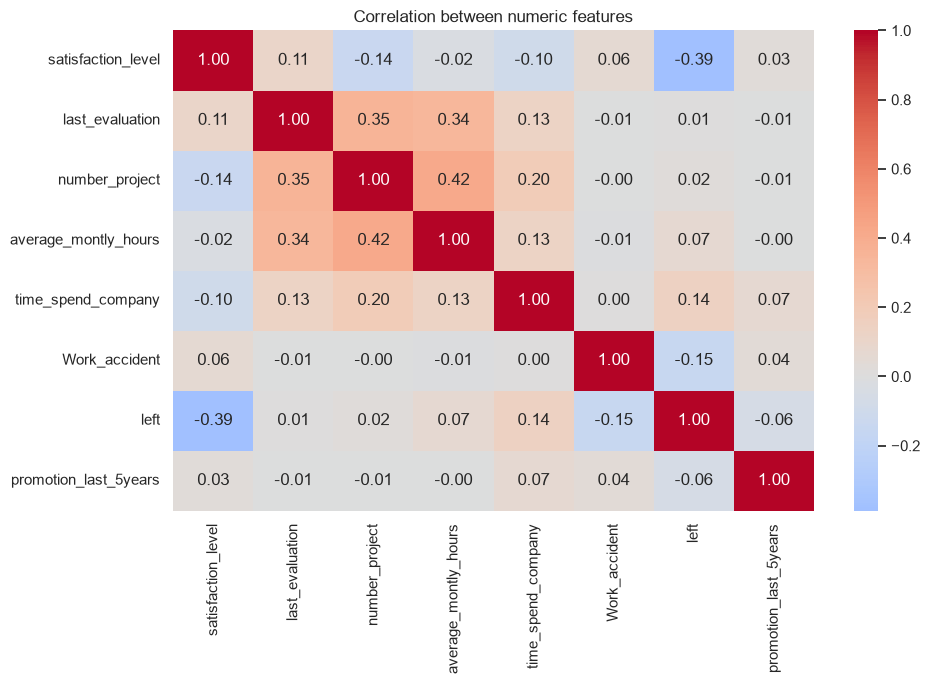

Correlation of each feature with 'left':
satisfaction_level      -0.39
Work_accident           -0.15
promotion_last_5years   -0.06
last_evaluation          0.01
number_project           0.02
average_montly_hours     0.07
time_spend_company       0.14
Name: left, dtype: float64


In [5]:
numeric_cols = df.select_dtypes(include="number").columns

plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.tight_layout()
plt.show()

print("Correlation of each feature with 'left':")
print(df[numeric_cols].corr()["left"].drop("left").sort_values().round(2))

**Inference:** `satisfaction_level` has the strongest correlation with leaving (about -0.39): the less satisfied someone is, the more likely they are to leave. Most other features are weakly correlated on their own, which suggests their effect is not a straight line.

### 2.2 Distribution plots: satisfaction, evaluation and monthly hours

Each chart shows how values are spread, split by people who stayed (blue) and left (red).

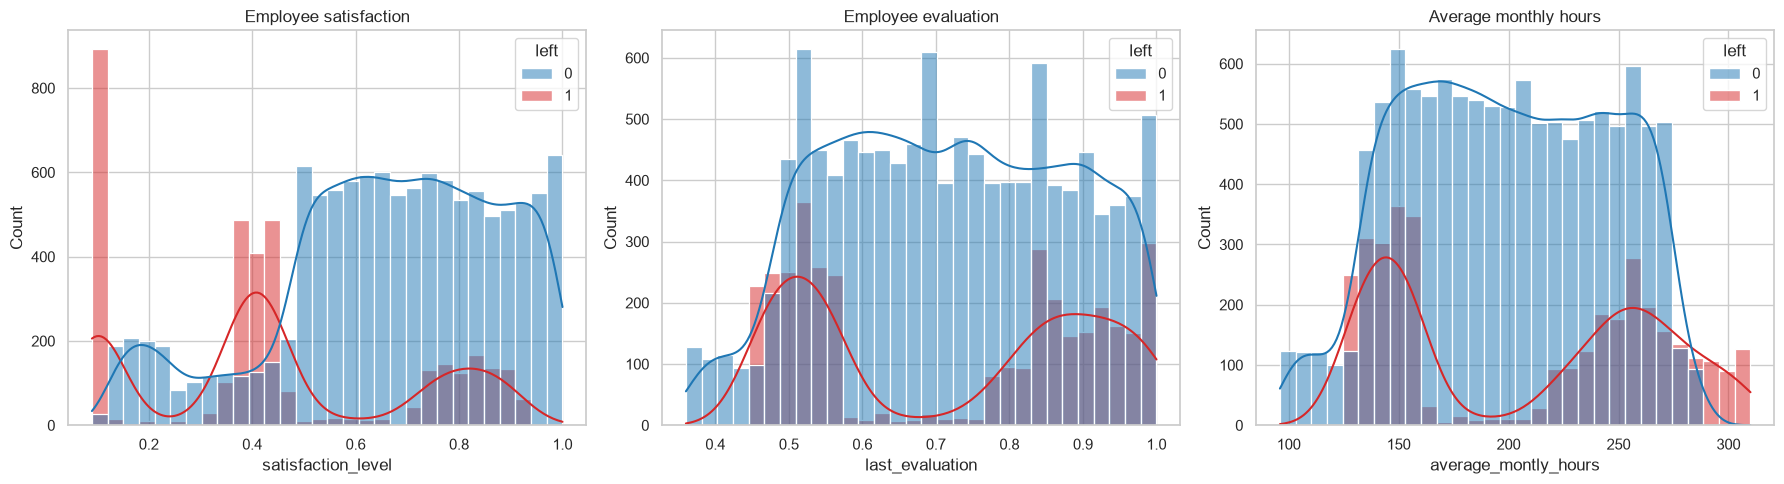

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
features = ["satisfaction_level", "last_evaluation", "average_montly_hours"]
titles = ["Employee satisfaction", "Employee evaluation", "Average monthly hours"]

for ax, col, title in zip(axes, features, titles):
    sns.histplot(data=df, x=col, hue="left", kde=True, bins=30, ax=ax,
                 palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(title)

plt.tight_layout()
plt.show()

**Inference:** leavers bunch up in distinct groups: very low satisfaction, middling satisfaction with low evaluations and low hours, and high evaluations with very long hours. These groups reappear in the clustering step.

### 2.3 Project count of employees who left and stayed

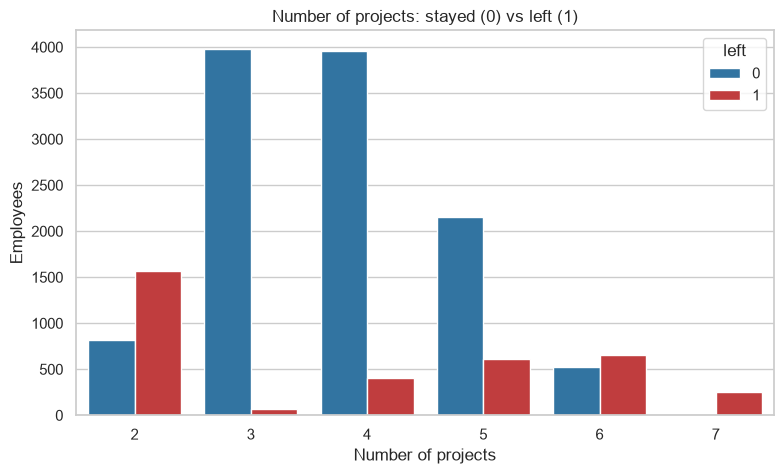

Percentage who left, by number of projects:
number_project
2     65.6%
3      1.8%
4      9.4%
5     22.2%
6     55.8%
7    100.0%
Name: left, dtype: str


In [7]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="number_project", hue="left", palette={0: "tab:blue", 1: "tab:red"})
plt.title("Number of projects: stayed (0) vs left (1)")
plt.xlabel("Number of projects")
plt.ylabel("Employees")
plt.show()

# Share of employees who left, for each project count
leave_rate = (df.groupby("number_project")["left"].mean() * 100).round(1)
print("Percentage who left, by number of projects:")
print(leave_rate.astype(str) + "%")

**Inference:** turnover follows a U-shape. People with only 2 projects leave often (they may feel under-used), people with 3–4 projects mostly stay, and people with 6–7 projects leave very often (likely burnout). Workload at both extremes is a risk.

## Step 3: Clustering the employees who left

We take only the employees who left and group them with **K-means** into 3 clusters, using satisfaction and evaluation. K-means places 3 centre points and assigns each person to the nearest one.

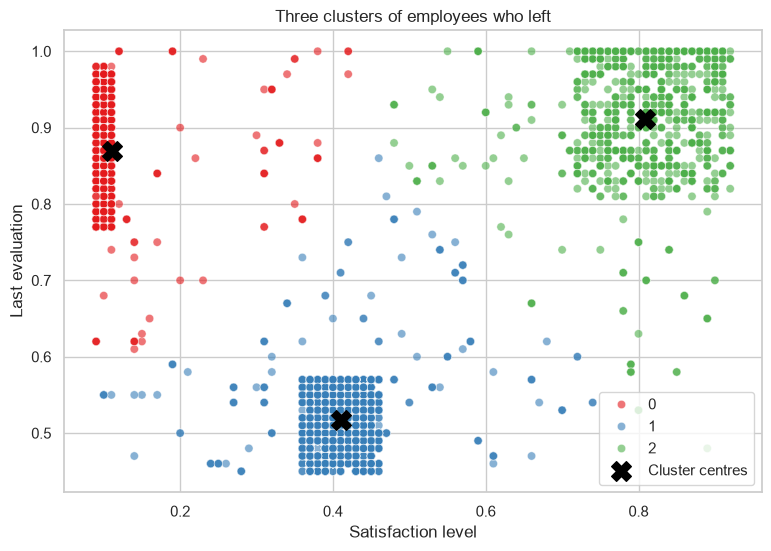

Cluster centres:
   satisfaction  evaluation
0          0.11        0.87
1          0.41        0.52
2          0.81        0.91

Employees per cluster:
cluster
0     944
1    1650
2     977
Name: count, dtype: int64


In [8]:
left_df = df.loc[df["left"] == 1, ["satisfaction_level", "last_evaluation", "left"]].copy()
X_cluster = left_df[["satisfaction_level", "last_evaluation"]]

kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
left_df["cluster"] = kmeans.fit_predict(X_cluster)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=left_df, x="satisfaction_level", y="last_evaluation",
                hue="cluster", palette="Set1", alpha=0.6)
centres = kmeans.cluster_centers_
plt.scatter(centres[:, 0], centres[:, 1], c="black", s=200, marker="X", label="Cluster centres")
plt.title("Three clusters of employees who left")
plt.xlabel("Satisfaction level")
plt.ylabel("Last evaluation")
plt.legend()
plt.show()

print("Cluster centres:")
print(pd.DataFrame(centres, columns=["satisfaction", "evaluation"]).round(2))
print("\nEmployees per cluster:")
print(left_df["cluster"].value_counts().sort_index())

**Thoughts on the clusters** (cluster numbers can differ between runs, so match them by their centres):

| Cluster profile | Who they are | Retention idea |
| --- | --- | --- |
| Low satisfaction, high evaluation | Overworked high performers who burned out | Rebalance workload, recognise effort |
| Middling satisfaction, low evaluation | Disengaged or under-used employees | Coaching, clearer goals, better role fit |
| High satisfaction, high evaluation | Happy high performers who left anyway, likely for better offers | Growth paths and pay reviews |

## Step 4: Handling class imbalance with SMOTE

### 4.1 Convert categorical columns to numbers

Models need numbers, so `department` and `salary` become one 0/1 column per category (**one-hot encoding** with `get_dummies`). We then combine them with the numeric columns.

In [9]:
categorical_cols = ["department", "salary"]
numeric_features = [c for c in df.columns if c not in categorical_cols + ["left"]]

df_categorical = pd.get_dummies(df[categorical_cols], dtype=int)
df_numeric = df[numeric_features]

X = pd.concat([df_numeric, df_categorical], axis=1)   # features
y = df["left"]                                         # target

print("Feature table shape:", X.shape)
X.head()

Feature table shape: (14999, 20)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,department_IT,department_RandD,department_accounting,department_hr,department_management,department_marketing,department_product_mng,department_sales,department_support,department_technical,salary_high,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,0.80,0.86,5,262,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
2,0.11,0.88,7,272,4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1
3,0.72,0.87,5,223,5,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
4,0.37,0.52,2,159,3,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0


### 4.2 Stratified train-test split (80:20, random_state=123)

**Stratified** means both sets keep the same 76:24 ratio of stayers to leavers. The test set is locked away until the final evaluation.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, "  Test set:", X_test.shape)
print(f"Leavers in training: {y_train.mean():.1%}   Leavers in test: {y_test.mean():.1%}")

Training set: (11999, 20)   Test set: (3000, 20)
Leavers in training: 23.8%   Leavers in test: 23.8%


### 4.3 Upsample the training set with SMOTE

SMOTE creates synthetic examples of the rare class (leavers) by drawing new points between real leavers and their nearest neighbours. It is applied to the **training set only**, so the test set stays 100% real.

Before SMOTE: {0: 9142, 1: 2857}
After SMOTE:  {0: 9142, 1: 9142}


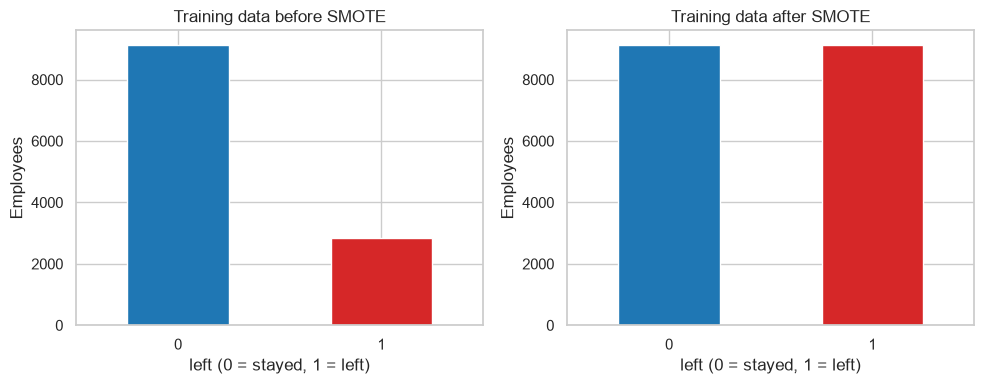

In [11]:
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE: ", y_train_sm.value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=["tab:blue", "tab:red"],
                                             title="Training data before SMOTE")
y_train_sm.value_counts().sort_index().plot.bar(ax=axes[1], color=["tab:blue", "tab:red"],
                                                title="Training data after SMOTE")
for ax in axes:
    ax.set_xlabel("left (0 = stayed, 1 = left)")
    ax.set_ylabel("Employees")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## Step 5: 5-fold cross-validation and classification reports

We train **logistic regression**, **random forest** and **gradient boosting** with 5-fold cross-validation: the training data is split into 5 parts, and each part takes a turn as the validation set.

Good practice: we put SMOTE *inside* a pipeline, so it only rebalances the 4 training folds each time and never the validation fold. This avoids synthetic rows leaking into the score. Logistic regression also gets scaled inputs, which it needs; tree models don't.

===== Logistic Regression: 5-fold cross-validation =====
              precision    recall  f1-score   support

           0      0.893     0.811     0.850      9142
           1      0.532     0.688     0.600      2857

    accuracy                          0.782     11999
   macro avg      0.712     0.749     0.725     11999
weighted avg      0.807     0.782     0.790     11999



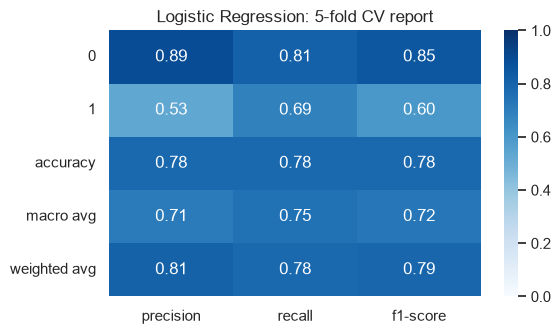

===== Random Forest: 5-fold cross-validation =====
              precision    recall  f1-score   support

           0      0.987     0.994     0.990      9142
           1      0.979     0.959     0.969      2857

    accuracy                          0.985     11999
   macro avg      0.983     0.976     0.980     11999
weighted avg      0.985     0.985     0.985     11999



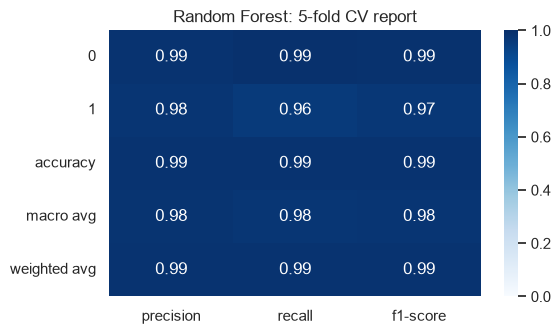

===== Gradient Boosting: 5-fold cross-validation =====
              precision    recall  f1-score   support

           0      0.980     0.978     0.979      9142
           1      0.929     0.935     0.932      2857

    accuracy                          0.968     11999
   macro avg      0.954     0.956     0.955     11999
weighted avg      0.968     0.968     0.968     11999



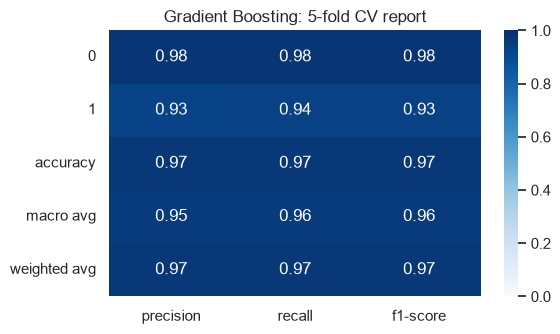

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

def make_cv_pipeline(model):
    """SMOTE inside each fold; scaling only for logistic regression."""
    steps = [("smote", SMOTE(random_state=RANDOM_STATE))]
    if isinstance(model, LogisticRegression):
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)

def plot_classification_report(y_true, y_pred, title):
    """Draw the classification report as a colour-coded table."""
    report = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True)).T
    report = report.drop(columns="support")
    plt.figure(figsize=(6, 3.5))
    sns.heatmap(report, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
    plt.title(title)
    plt.tight_layout()
    plt.show()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, model in models.items():
    y_cv_pred = cross_val_predict(make_cv_pipeline(model), X_train, y_train, cv=cv)
    print(f"===== {name}: 5-fold cross-validation =====")
    print(classification_report(y_train, y_cv_pred, digits=3))
    plot_classification_report(y_train, y_cv_pred, f"{name}: 5-fold CV report")

**How to read a classification report:** for the `1` row (leavers), **precision** is how often a "will leave" prediction is right, **recall** is how many real leavers were caught, and **f1-score** balances the two.

## Step 6: Identify the best model

### 6.1 ROC curves and AUC on the test set

Each model is trained on the SMOTE-balanced training set from Step 4.3 and tested on the untouched test set. The ROC curve shows the trade-off between catching leavers and raising false alarms; AUC sums it up (0.5 = random, 1 = perfect).

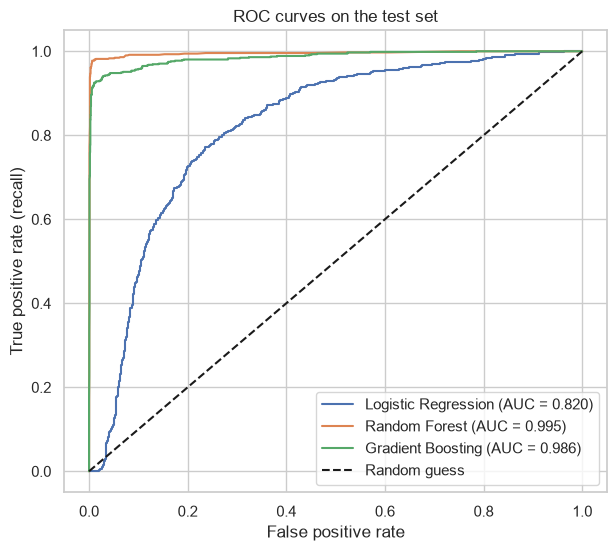

In [13]:
fitted, test_probs = {}, {}

plt.figure(figsize=(7, 6))
for name, model in models.items():
    if isinstance(model, LogisticRegression):
        clf = Pipeline([("scaler", StandardScaler()), ("model", model)])
    else:
        clf = model
    clf.fit(X_train_sm, y_train_sm)
    fitted[name] = clf
    test_probs[name] = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, test_probs[name]):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend()
plt.show()

### 6.2 Confusion matrix for each model

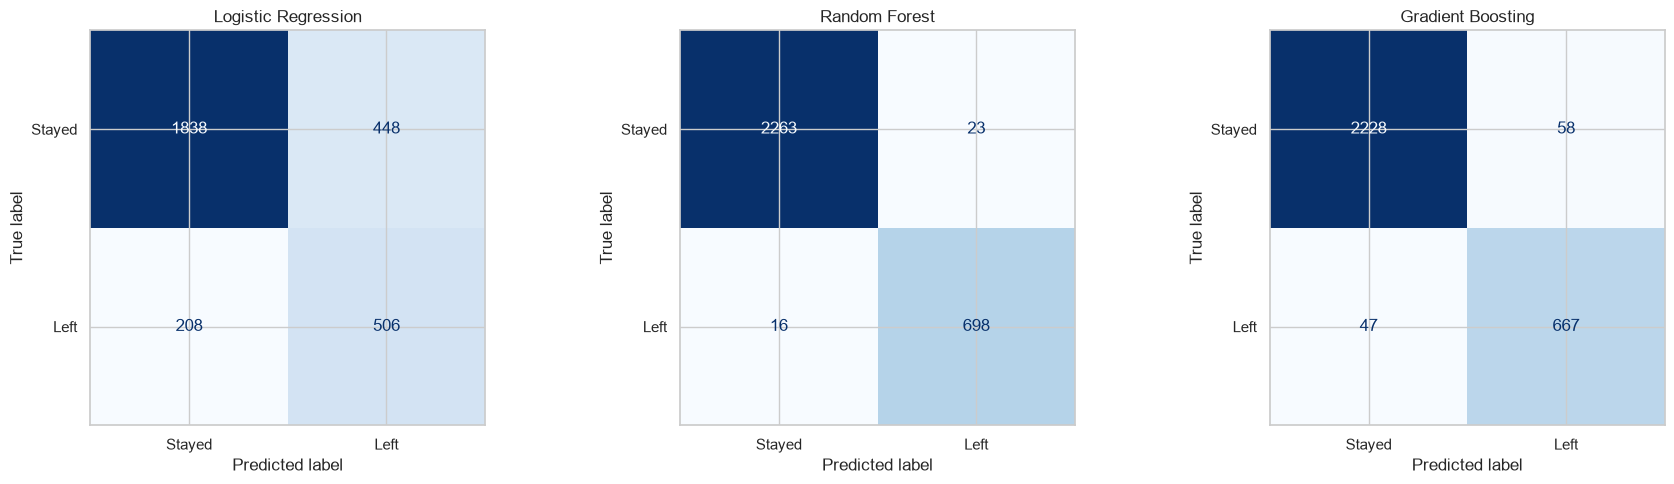

,Recall (left),Precision (left),ROC-AUC
Model,,,
Logistic Regression,0.709,0.530,0.820
Random Forest,0.978,0.968,0.995
Gradient Boosting,0.934,0.920,0.986


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
summary = []

for ax, (name, clf) in zip(axes, fitted.items()):
    y_pred = clf.predict(X_test)
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Stayed", "Left"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    summary.append({
        "Model": name,
        "Recall (left)": recall_score(y_test, y_pred),
        "Precision (left)": precision_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, test_probs[name]),
    })

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary).set_index("Model").round(3)
summary_df

### 6.3 Recall or precision?

**Recall** matters most here. A false negative (missing someone who is about to leave) is expensive: HR loses the chance to act, and replacing an employee costs hiring and training. A false positive only costs a friendly check-in conversation. So we pick the model with the highest recall for leavers, using ROC-AUC as the tie-breaker.

In [15]:
best_name = summary_df.sort_values(["Recall (left)", "ROC-AUC"], ascending=False).index[0]
print("Best model:", best_name)
print(summary_df.loc[best_name])

Best model: Random Forest
Recall (left)       0.978
Precision (left)    0.968
ROC-AUC             0.995
Name: Random Forest, dtype: float64


## Step 7: Retention strategies for targeted employees

### 7.1 Predict each test employee's probability of leaving and assign a risk zone

Zones from the brief: Safe (below 20%), Low risk (20–60%), Medium risk (60–90%), High risk (above 90%). The brief's ranges leave exactly 20%, 60% and 90% undefined, so here each boundary value belongs to the higher zone.

,employees,average_probability,share_who_actually_left
risk_zone,,,
Safe Zone (Green),2157,0.03,0.01
Low-Risk Zone (Yellow),131,0.31,0.04
Medium-Risk Zone (Orange),64,0.76,0.84
High-Risk Zone (Red),648,0.99,0.99


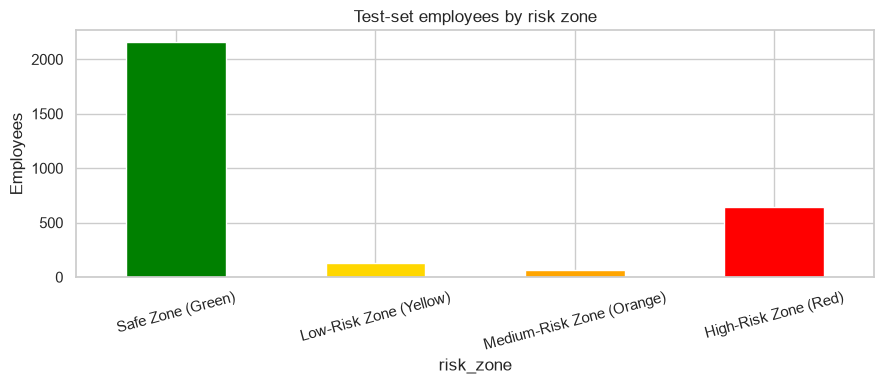


Saved per-employee scores and zones to employee_risk_zones.csv


In [16]:
best_model = fitted[best_name]

results = X_test.copy()
results["actually_left"] = y_test.values
results["turnover_probability"] = best_model.predict_proba(X_test)[:, 1]

bins = [0, 0.2, 0.6, 0.9, 1.0001]
labels = ["Safe Zone (Green)", "Low-Risk Zone (Yellow)", "Medium-Risk Zone (Orange)", "High-Risk Zone (Red)"]
results["risk_zone"] = pd.cut(results["turnover_probability"], bins=bins, labels=labels, right=False)

zone_summary = results.groupby("risk_zone", observed=False).agg(
    employees=("turnover_probability", "size"),
    average_probability=("turnover_probability", "mean"),
    share_who_actually_left=("actually_left", "mean"),
)
display(zone_summary.round(2))

zone_summary["employees"].plot.bar(color=["green", "gold", "orange", "red"], figsize=(9, 4),
                                   title="Test-set employees by risk zone")
plt.ylabel("Employees")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

results.to_csv("employee_risk_zones.csv", index=False)
print("\nSaved per-employee scores and zones to employee_risk_zones.csv")

### 7.2 Retention strategy for each zone

| Zone | Chance of leaving | Suggested action |
| --- | --- | --- |
| Safe Zone (Green) | Below 20% | Keep engagement up: recognition, regular feedback, fair workload |
| Low-Risk Zone (Yellow) | 20% to 60% | Career conversations, development plans, regular check-ins with the manager |
| Medium-Risk Zone (Orange) | 60% to 90% | Review workload and project count, offer training, promotion paths or a pay review |
| High-Risk Zone (Red) | Above 90% | One-to-one with the manager this week, a targeted retention offer, fix overwork or under-use quickly |

## Conclusion

- Satisfaction is the strongest single driver of turnover, and workload is risky at both extremes.
- Leavers fall into three groups: overworked high performers, disengaged employees and satisfied high performers who left anyway.
- With SMOTE and 5-fold cross-validation, tree ensembles outperform logistic regression; the best model is chosen by recall for leavers.
- Risk zones turn each prediction into a concrete action for HR.